# Exploratory analysis of the Moscow food-service market

- Author: Nurassyl Molshin
- Date: 24.10.2026

### Project goals and tasks

**Goal:** help the investors of the Shut Up and Take My Money fund understand how the Moscow food-service market is structured, so they can choose a format, district and price level for a new venue.

**Tasks:**
1. Load and inspect the venue and price data and merge them into one dataframe.
2. Preprocess: data types, missing values, duplicates, and an `is_24_7` flag for round-the-clock venues.
3. Explore categories, districts, the share of chain venues, seating, ratings and average bill.
4. Find what venue rating is most strongly associated with and look at the biggest chains.
5. Write up conclusions and recommendations for the client.

### Data description

The data comes from Yandex Maps and Yandex Business, summer 2022.

**`/datasets/rest_info.csv`** — venue information:
- `name` — venue name;
- `address` — address;
- `district` — Moscow administrative district (okrug);
- `category` — category ("cafe", "pizzeria", "coffee shop", etc.);
- `hours` — opening days and hours;
- `rating` — Yandex Maps user rating (max 5.0);
- `chain` — chain venue (1) or not (0);
- `seats` — number of seats.

**`/datasets/rest_price.csv`** — price information:
- `price` — price category ("low", "medium", "above average", "high");
- `avg_bill` — string with the average order cost, e.g. "Average bill:1000–1500 RUB";
- `middle_avg_bill` — numeric estimate of the average bill (only for strings starting with "Average bill");
- `middle_coffee_cup` — numeric estimate of a cappuccino price (only for cappuccino strings).

The two files are linked by the `id` column. This notebook uses the **English versions** of the datasets (`rest_info_en.csv`, `rest_price_en.csv`): categories, districts, price levels, hours and bill strings are translated, venue names and street names are transliterated from Russian.

### Project contents

1. Loading the data and first look
2. Data preprocessing
3. Exploratory data analysis (tasks 1–8)
4. Final conclusion and recommendations

---

## 1. Loading the data and first look

- Load the Moscow food-service data. File paths: `/datasets/rest_info.csv` and `/datasets/rest_price.csv`.

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# phik is used for correlation with categorical features; install it if missing
try:
    import phik
except ImportError:
    %pip install phik -q
    import phik

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

In [3]:
# Load the English versions of the datasets (keep the CSVs in the same folder as this notebook)
rest_info = pd.read_csv('../datasets/rest_info_en.csv')
rest_price = pd.read_csv('../datasets/rest_price_en.csv')

- Get to know the data and study the general information about it.

In [4]:
rest_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWfli,cafe,"Moscow, street Dybenko, 7/1",Northern Administrative District,"daily, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Chetyre komnaty,restaurant,"Moscow, street Dybenko, 36, bldg. 1",Northern Administrative District,"daily, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Khazri,cafe,"Moscow, Klyazminskaya street, 15",Northern Administrative District,"Mon-Thu 11:00–02:00; Fri,Sat 11:00–05:00; Sun ...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,coffee shop,"Moscow, street Marshala Fedorenko, 12",Northern Administrative District,"daily, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Il Marko,pizzeria,"Moscow, Pravoberezhnaya street, 1B",Northern Administrative District,"daily, 10:00–22:00",5.0,1,148.0


In [5]:
rest_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   str    
 1   name      8406 non-null   str    
 2   category  8406 non-null   str    
 3   address   8406 non-null   str    
 4   district  8406 non-null   str    
 5   hours     7870 non-null   str    
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), str(6)
memory usage: 591.2 KB


In [6]:
rest_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,above average,Average bill:1500–1600 RUB,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,medium,Average bill:from 1000 RUB,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Cappuccino price:155–185 RUB,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,medium,Average bill:400–600 RUB,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,medium,NaN,NaN,NaN


In [7]:
rest_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   str    
 1   price              3315 non-null   str    
 2   avg_bill           3816 non-null   str    
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), str(3)
memory usage: 158.6 KB


In [9]:
# Missing values as shares, to see the scale
print('rest_info:')
print(rest_info.isna().mean().round(3).sort_values(ascending=False))
print()
print('rest_price:')
print(rest_price.isna().mean().round(3).sort_values(ascending=False))

rest_info:
seats       0.430
hours       0.064
id          0.000
name        0.000
category    0.000
district    0.000
address     0.000
rating      0.000
chain       0.000
dtype: float64

rest_price:
middle_coffee_cup    0.868
middle_avg_bill      0.224
price                0.183
avg_bill             0.060
id                   0.000
dtype: float64


In [10]:
# Quick look at categorical values and numeric ranges
print(rest_info['category'].value_counts(), '\n')
print(rest_info['district'].value_counts(), '\n')
print(rest_price['price'].value_counts(dropna=False), '\n')
rest_info[['rating', 'chain', 'seats']].describe()

category
cafe           2378
restaurant     2043
coffee shop    1413
bar/pub         765
pizzeria        633
fast food       603
canteen         315
bakery          256
Name: count, dtype: int64 

district
Central Administrative District          2242
Northern Administrative District          900
Southern Administrative District          892
North-Eastern Administrative District     891
Western Administrative District           851
Eastern Administrative District           798
South-Eastern Administrative District     714
South-Western Administrative District     709
North-Western Administrative District     409
Name: count, dtype: int64 

price
medium           2117
NaN               743
above average     564
high              478
low               156
Name: count, dtype: int64 



,rating,chain,seats
count,8406.000000,8406.000000,4795.000000
mean,4.229895,0.381275,108.421689
std,0.470348,0.485729,122.833396
min,1.000000,0.000000,0.000000
25%,4.100000,0.000000,40.000000
50%,4.300000,0.000000,75.000000
75%,4.400000,1.000000,140.000000
max,5.000000,1.000000,1288.000000


In [9]:
# Are all rest_price ids present in rest_info, and are ids unique?
print('Unique ids in rest_info:', rest_info['id'].nunique(), 'of', len(rest_info))
print('Unique ids in rest_price:', rest_price['id'].nunique(), 'of', len(rest_price))
print('rest_price ids missing from rest_info:', len(set(rest_price['id']) - set(rest_info['id'])))

Unique ids in rest_info: 8406 of 8406
Unique ids in rest_price: 4058 of 4058
rest_price ids missing from rest_info: 0


---

### Interim conclusion


`rest_info` has 8406 venues and 9 columns, `rest_price` has 4058 rows and 5 columns. The data matches the description, `id` is unique in both files, and every `id` in `rest_price` exists in `rest_info`. So price information is available for fewer than half of the venues.

Observations:
- Missing values in `rest_info`: `seats` (about 43%) and `hours` (about 6%). In `rest_price` there are many gaps in `middle_coffee_cup` (87% — expected, it is only filled for coffee shops with a cappuccino price), `middle_avg_bill` (22%), `price` (18%) and `avg_bill` (6%).
- Data types are mostly fine. `seats` is stored as `float64` only because of the gaps — semantically it is an integer. `chain` is `int64` with 0/1 values, which is fine.
- Ratings are within 1–5, no issues. `seats` has a minimum of 0 and a maximum of 1288 — clearly there are outliers, to be checked later.
- Names were transliterated from Russian, so the same brand can appear in different spellings or cases.
- Venue names are written in different cases, so they need normalising before searching for implicit duplicates.

### Building a single dataframe

- Merge the two datasets into one that you will keep working with.

In [10]:
# Merge on id. A left join keeps venues that have no price information
df = rest_info.merge(rest_price, on='id', how='left')
print(df.shape)
df.head()

(8406, 13)


,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWfli,cafe,"Moscow, street Dybenko, 7/1",Northern Administrative District,"daily, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Chetyre komnaty,restaurant,"Moscow, street Dybenko, 36, bldg. 1",Northern Administrative District,"daily, 10:00–22:00",4.5,0,4.0,above average,Average bill:1500–1600 RUB,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Khazri,cafe,"Moscow, Klyazminskaya street, 15",Northern Administrative District,"Mon-Thu 11:00–02:00; Fri,Sat 11:00–05:00; Sun ...",4.6,0,45.0,medium,Average bill:from 1000 RUB,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,coffee shop,"Moscow, street Marshala Fedorenko, 12",Northern Administrative District,"daily, 09:00–22:00",5.0,0,NaN,NaN,Cappuccino price:155–185 RUB,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Il Marko,pizzeria,"Moscow, Pravoberezhnaya street, 1B",Northern Administrative District,"daily, 10:00–22:00",5.0,1,148.0,medium,Average bill:400–600 RUB,500.0,NaN


## 2. Data preprocessing

Prepare the data for exploratory analysis:

- Check that the data types are correct and convert them if needed.

In [11]:
# seats is an integer by meaning; Int64 supports missing values
df['seats'] = df['seats'].astype('Int64')
# chain is a 0/1 flag, int8 is enough
df['chain'] = df['chain'].astype('int8')
df.dtypes

id                       str
name                     str
category                 str
address                  str
district                 str
hours                    str
rating               float64
chain                   int8
seats                  Int64
price                    str
avg_bill                 str
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

- Study the missing values: count them in each column, look at rows with missing values and suggest hypotheses about why they appear. Handle the missing values: you can replace them with a specific value, delete rows with gaps, or leave them as they are.

In [12]:
# Count and share of missing values after the merge
missing = pd.DataFrame({'count': df.isna().sum(), 'share': df.isna().mean().round(3)})
missing[missing['count'] > 0].sort_values('count', ascending=False)

,count,share
middle_coffee_cup,7871,0.936
middle_avg_bill,5257,0.625
price,5091,0.606
avg_bill,4590,0.546
seats,3611,0.430
hours,536,0.064


In [13]:
# Is missing seats data related to category or chain status?
print(df.groupby('category')['seats'].apply(lambda s: s.isna().mean()).round(2).sort_values())
print()
print(df.groupby('chain')['seats'].apply(lambda s: s.isna().mean()).round(2))

category
pizzeria       0.33
restaurant     0.38
bar/pub        0.39
bakery         0.42
fast food      0.42
coffee shop    0.47
canteen        0.48
cafe           0.49
Name: seats, dtype: float64

chain
0    0.45
1    0.40
Name: seats, dtype: float64


In [14]:
# Missing price: how many are simply because the venue has no row in rest_price
no_price_row = ~df['id'].isin(rest_price['id'])
print('Venues without a rest_price row:', no_price_row.sum())
print('Missing price among venues that do have a row:', df.loc[~no_price_row, 'price'].isna().sum())

# avg_bill present but middle_avg_bill empty — these are cappuccino, beer etc. strings
df.loc[df['avg_bill'].notna() & df['middle_avg_bill'].isna(), 'avg_bill'].str.split(':').str[0].value_counts()

Venues without a rest_price row: 4348
Missing price among venues that do have a row: 743


avg_bill
Cappuccino price    535
Beer glass price    132
Name: count, dtype: int64

Hypotheses for the missing values:
- **`price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`** — mostly because 4348 venues have no row in `rest_price` at all: owners didn't fill in prices on Yandex Business. `middle_avg_bill` is also empty where `avg_bill` is not an "average bill" but a cappuccino or beer price, so those gaps exist by construction.
- **`seats`** — the number of seats is usually filled in by the owner, and many don't. The share of gaps ranges from 33% (pizzerias) to 49% (cafes), slightly lower for chains (40% vs 45%) — no strong pattern, chains just fill in their listings more carefully.
- **`hours`** — opening hours were not specified on the listing.

Handling: I **don't fill** the gaps. Imputing a median for `seats` or `middle_avg_bill` would heavily distort the distributions (almost half the values are missing), and deleting rows would lose more than half the dataset. For each question I'll use the rows where the needed value exists. A missing `hours` value will mean `False` for `is_24_7`, since round-the-clock operation can't be confirmed.

- Check the data for explicit and implicit duplicates, e.g. venue name and address fields. To make the check easier, normalise the text columns, e.g. the venue name.

In [15]:
# Explicit duplicates: fully identical rows and repeated ids
print('Full duplicates:', df.duplicated().sum())
print('Duplicate ids:', df['id'].duplicated().sum())

Full duplicates: 0
Duplicate ids: 0


In [16]:
# Normalise text: lower case, trimmed
for col in ['name', 'address']:
    df[col] = df[col].str.strip()
df['name_norm'] = df['name'].str.lower()
df['address_norm'] = df['address'].str.lower()

# Implicit duplicates — the same name at the same address
implicit = df[df.duplicated(subset=['name_norm', 'address_norm'], keep=False)]
implicit.sort_values('name_norm')[['name', 'address', 'category', 'rating', 'chain', 'seats', 'hours']]

,name,address,category,rating,chain,seats,hours
416,Chaykhana Khalal,"Moscow, Smolnaya street, 24G, str. 6",restaurant,4.3,0,53,"daily, 24 hours"
450,Chaykhana Khalal,"Moscow, Smolnaya street, 24G, str. 6",restaurant,4.3,1,53,"daily, 24 hours"
3091,Khleb da Vypechka,"Moscow, Yartsevskaya street, 19",bakery,4.1,1,276,"daily, 09:00–22:00"
3109,Khleb da vypechka,"Moscow, Yartsevskaya street, 19",cafe,4.1,0,276,NaN
5314,Leon,"Moscow, street Metallurgov, 29A",restaurant,4.3,1,<NA>,Mon-Sat 11:00–23:00; Sun 12:00–23:00
5316,Leon,"Moscow, street Metallurgov, 29A",restaurant,4.4,0,<NA>,Mon-Sat 11:00–23:00; Sun 12:00–23:00
1430,More poke,"Moscow, Volokolamskoe highway, 11, str. 2",restaurant,4.2,0,188,"daily, 09:00–21:00"
1511,More Poke,"Moscow, Volokolamskoe highway, 11, str. 2",restaurant,4.2,1,188,"Mon-Thu 09:00–18:00; Fri,Sat 09:00–21:00; Sun ..."
2211,Rakovarnya Kleshni i Khvosty,"Moscow, prospekt Mira, 118",restaurant,4.4,0,150,"daily, 12:00–00:00"
2420,Rakovarnya Kleshni i khvosty,"Moscow, prospekt Mira, 118",bar/pub,4.4,1,150,"Mon-Thu 12:00–00:00; Fri,Sat 12:00–01:00; Sun ..."


In [17]:
# These are the same venues recorded twice (different case, category or hours).
# Keep the first record from each pair
rows_before = len(df)
df = df.drop_duplicates(subset=['name_norm', 'address_norm'], keep='first').reset_index(drop=True)
print(f'Rows removed: {rows_before - len(df)} ({(rows_before - len(df)) / rows_before:.2%}), remaining: {len(df)}')

Rows removed: 7 (0.08%), remaining: 8399


- For further work, create an `is_24_7` column marking whether the venue is open every day around the clock, i.e. 24/7:
  - boolean `True` — if the venue is open every day, around the clock;
  - boolean `False` — otherwise.

In [18]:
# How is round-the-clock operation written?
df.loc[df['hours'].str.contains('24 hours', na=False), 'hours'].value_counts().head(8)

hours
daily, 24 hours                                                                               729
Mon-Thu 08:00–23:00; Fri 08:00–00:00; Sat 24 hours; Sun 00:00–23:00                             3
Mon-Thu 07:30–23:00; Fri 07:30–00:00; Sat 24 hours; Sun 00:00–23:00                             2
Mon-Thu 08:00–23:00; Fri,Sat 24 hours; Sun 08:00–23:00                                          2
Mon 00:01–12:00, break 12:00–13:30; Tue-Thu 13:30–12:00; Fri 13:30–00:00; Sat,Sun 24 hours      1
Tue-Sun 24 hours                                                                                1
Sat 24 hours                                                                                    1
Fri-Sun 24 hours                                                                                1
Name: count, dtype: int64

In [19]:
# 24/7 means exactly "daily, 24 hours".
# Variants like "Fri,Sat 24 hours" don't count: not every day
df['is_24_7'] = df['hours'].eq('daily, 24 hours')
df['is_24_7'].value_counts()

is_24_7
False    7670
True      729
Name: count, dtype: int64

In [20]:
# Short district labels for charts: drop the "Administrative District" suffix
# and shorten "Northern" -> "North" etc.
district_short = {
    'Central Administrative District': 'Central',
    'Northern Administrative District': 'North',
    'North-Eastern Administrative District': 'North-East',
    'Eastern Administrative District': 'East',
    'South-Eastern Administrative District': 'South-East',
    'Southern Administrative District': 'South',
    'South-Western Administrative District': 'South-West',
    'Western Administrative District': 'West',
    'North-Western Administrative District': 'North-West',
}
df['district_short'] = df['district'].map(district_short)
df['district_short'].isna().sum()

np.int64(0)

---

### Interim conclusion

After preprocessing, write an interim conclusion about the work done. State the number or share of filtered data if you deleted anything.

What was done during preprocessing:
- Merged the two datasets on `id` with a left join — 8406 rows, of which 4348 have no price data.
- Converted `seats` to `Int64` (integer with missing-value support) and `chain` to `int8`.
- Left the missing values as they are: there are too many to impute without distortion, and dropping them would remove more than half the data. The main reason is that owners didn't fill in Yandex Business info, and in `middle_avg_bill`/`middle_coffee_cup` the gaps are built into the column logic.
- No explicit duplicates. After normalising names and addresses, 7 implicit duplicates were found (one venue recorded twice) and removed — **7 rows, or 0.08%** of the data. **8399** venues remain. Transliteration catches 3 more pairs than the Russian data does (e.g. two "Chaykhana Khalal" and two "Zefir" listings at the same address), because spelling differences in the Cyrillic originals collapse to the same Latin text.
- Added the `is_24_7` flag: **729** venues (≈8.7%) are open daily around the clock.
- Added short district names `district_short` for charts.

## 3. Exploratory data analysis
Carry out exploratory analysis of the data.

Use visualisations. Make sure the optimal chart type is chosen in each case and is properly formatted. A chart should have a title, clear axis labels, a legend if needed, and an appropriate size.

After each item, leave a short comment with a conclusion or discussion of the result. At the end of the step, summarise the results, highlighting the most important ones in your opinion.

---

### Task 1

Which venue categories are present in the data? Explore the number of venues in each category. Accompany the result with a suitable visualisation.

In [21]:
cat_counts = df['category'].value_counts()
pd.DataFrame({'venues': cat_counts, 'share, %': (cat_counts / len(df) * 100).round(1)})

,venues,"share, %"
category,,
cafe,2377,28.3
restaurant,2040,24.3
coffee shop,1411,16.8
bar/pub,764,9.1
pizzeria,633,7.5
fast food,603,7.2
canteen,315,3.8
bakery,256,3.0


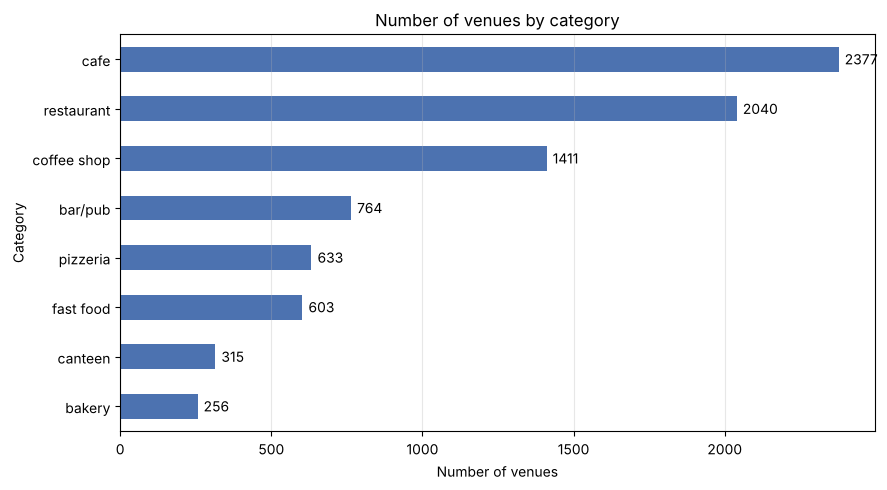

In [22]:
plt.figure(figsize=(9, 5))
ax = cat_counts.sort_values().plot(kind='barh', color='#4C72B0')
for i, v in enumerate(cat_counts.sort_values()):
    ax.text(v + 20, i, str(v), va='center')
plt.title('Number of venues by category')
plt.xlabel('Number of venues')
plt.ylabel('Category')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

There are 8 categories. The most common are cafes (2377, 28%) and restaurants (2040, 24%) — together more than half the market. Next come coffee shops (1411, 17%) and bars/pubs (764, 9%). Canteens and bakeries are the rarest at 3–4% each. A horizontal bar chart works best here: there are few categories and they're easy to compare by bar length.

---

### Task 2

Which Moscow administrative districts are present in the data? Explore the distribution of venues across the districts, and separately the distribution of venues of each category in the Central Administrative District. Accompany the result with suitable visualisations.

In [23]:
district_counts = df['district_short'].value_counts()
pd.DataFrame({'venues': district_counts, 'share, %': (district_counts / len(df) * 100).round(1)})

,venues,"share, %"
district_short,,
Central,2242,26.7
North,898,10.7
South,892,10.6
North-East,890,10.6
West,848,10.1
East,797,9.5
South-East,714,8.5
South-West,709,8.4
North-West,409,4.9


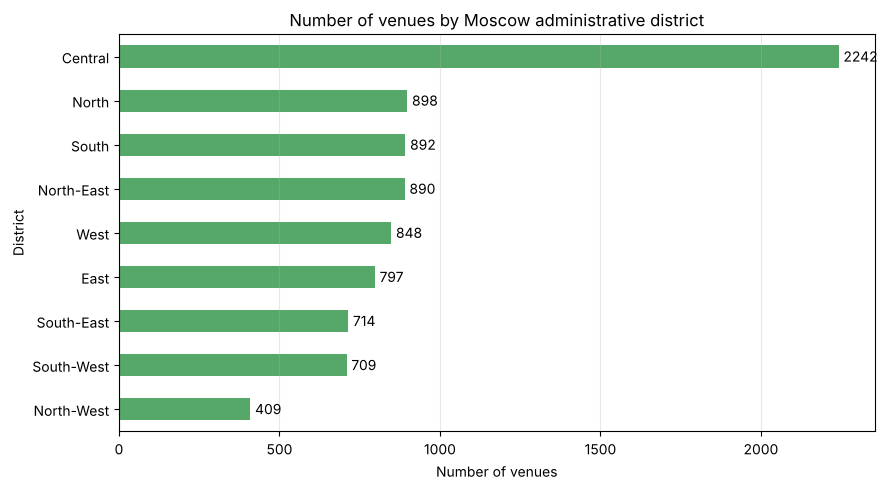

In [24]:
plt.figure(figsize=(9, 5))
ax = district_counts.sort_values().plot(kind='barh', color='#55A868')
for i, v in enumerate(district_counts.sort_values()):
    ax.text(v + 15, i, str(v), va='center')
plt.title('Number of venues by Moscow administrative district')
plt.xlabel('Number of venues')
plt.ylabel('District')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

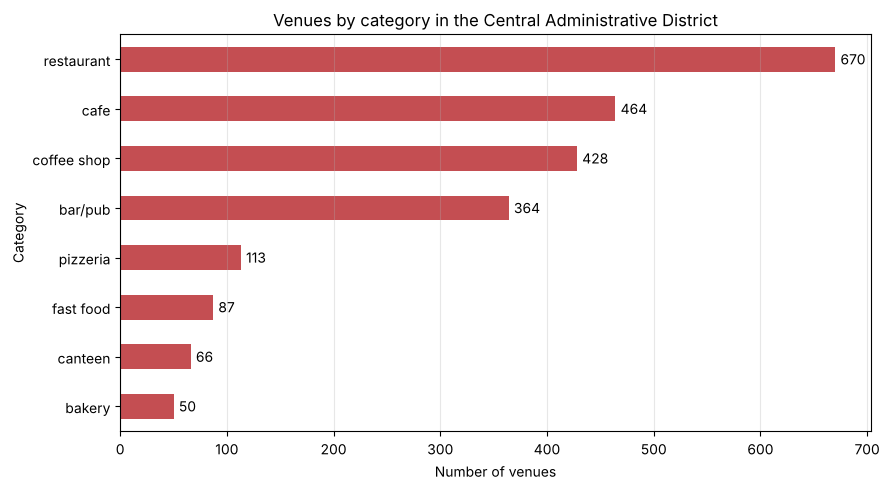

In [25]:
# Categories inside the Central district
cao_counts = df.loc[df['district_short'] == 'Central', 'category'].value_counts()

plt.figure(figsize=(9, 5))
ax = cao_counts.sort_values().plot(kind='barh', color='#C44E52')
for i, v in enumerate(cao_counts.sort_values()):
    ax.text(v + 5, i, str(v), va='center')
plt.title('Venues by category in the Central Administrative District')
plt.xlabel('Number of venues')
plt.ylabel('Category')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

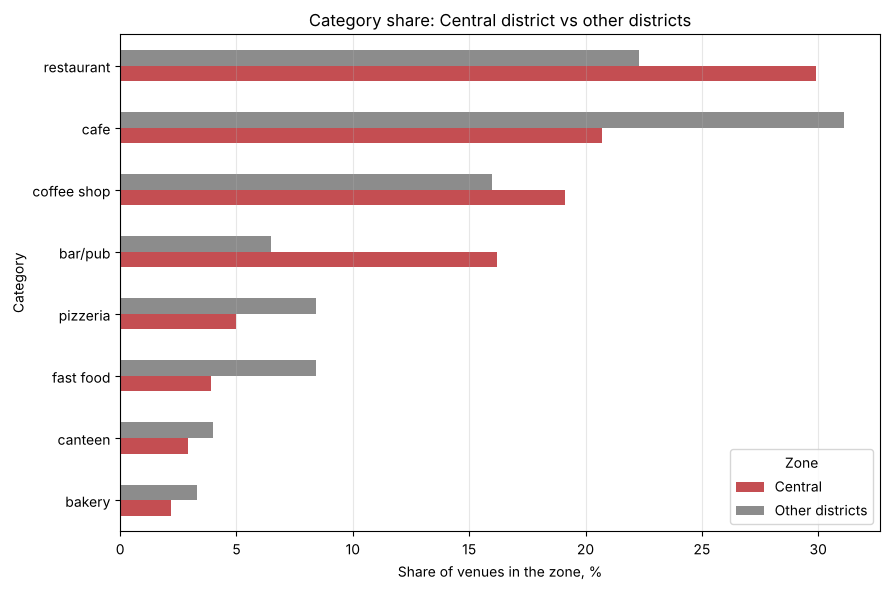

In [26]:
# Compare the category mix in the Central district vs other districts (as shares)
cat_share = (df.assign(zone=np.where(df['district_short'] == 'Central', 'Central', 'Other districts'))
               .groupby('zone')['category'].value_counts(normalize=True)
               .unstack(0).mul(100).round(1)
               .sort_values('Central'))

cat_share.plot(kind='barh', figsize=(9, 6), color=['#C44E52', '#8C8C8C'])
plt.title('Category share: Central district vs other districts')
plt.xlabel('Share of venues in the zone, %')
plt.ylabel('Category')
plt.legend(title='Zone')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

All 9 Moscow administrative districts are present (New Moscow and Zelenograd aren't in the data). The Central district stands out sharply: **2242 venues, almost 27%** of the total — more than the next two districts combined. The other districts are roughly equal (700–900 venues), only the North-West has noticeably fewer — 409.

Inside the Central district, restaurants come first (670), not cafes as in the city overall. Bars and pubs make up 16% in the centre vs 6% elsewhere — the centre is clearly about evening leisure. Cafes, fast food and canteens, on the other hand, have a smaller share in the centre than in outer districts.

---

### Task 3

Explore the ratio of chain and non-chain venues overall and by category. Which are more common — chain or non-chain venues? Which categories are more often chains? Explore the data, answer the questions and build the necessary visualisations.

chain
non-chain    5198
chain        3201
Name: count, dtype: int64
chain
non-chain    61.9
chain        38.1
Name: count, dtype: float64


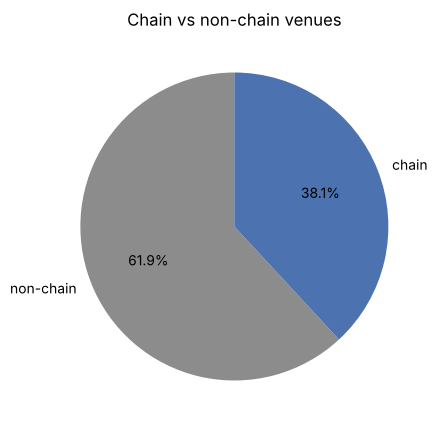

In [27]:
chain_counts = df['chain'].map({0: 'non-chain', 1: 'chain'}).value_counts()
print(chain_counts)
print((chain_counts / len(df) * 100).round(1))

plt.figure(figsize=(5, 5))
plt.pie(chain_counts, labels=chain_counts.index, autopct='%1.1f%%', startangle=90,
        colors=['#8C8C8C', '#4C72B0'])
plt.title('Chain vs non-chain venues')
plt.show()

In [28]:
# Share of chain venues within each category
chain_by_cat = df.groupby('category')['chain'].agg(['sum', 'count', 'mean']).sort_values('mean')
chain_by_cat.columns = ['chain', 'total', 'chain share']
chain_by_cat['chain share'] = chain_by_cat['chain share'].round(3)
chain_by_cat.sort_values('chain share', ascending=False)

,chain,total,chain share
category,,,
bakery,157,256,0.613
pizzeria,330,633,0.521
coffee shop,719,1411,0.510
fast food,232,603,0.385
restaurant,728,2040,0.357
cafe,779,2377,0.328
canteen,88,315,0.279
bar/pub,168,764,0.220


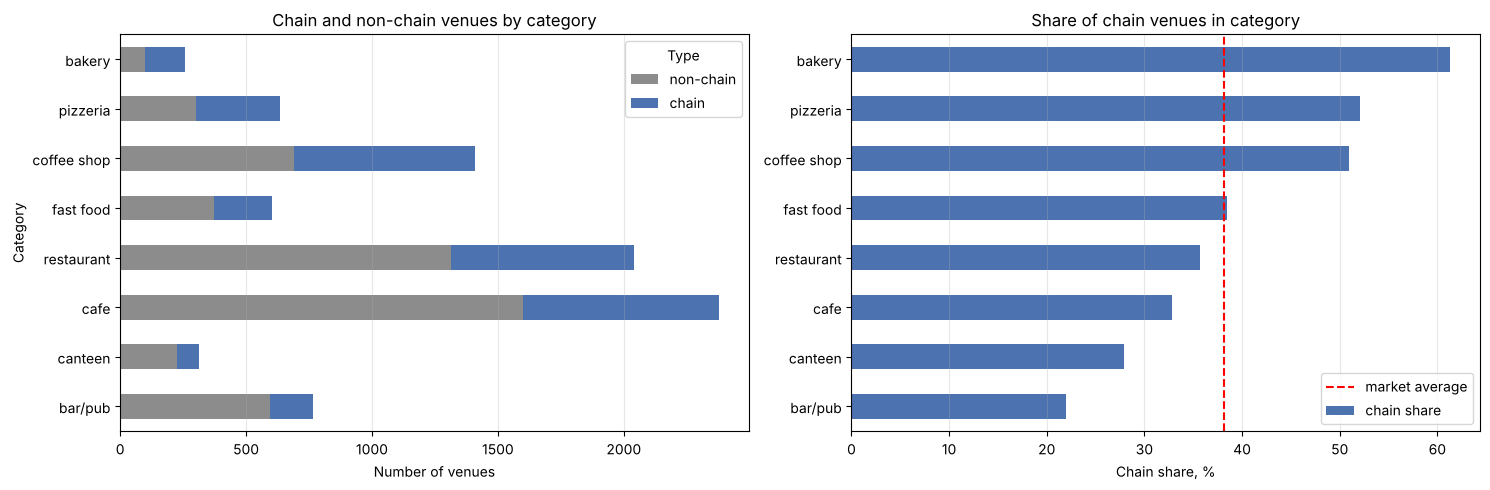

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left — absolute counts (stacked), right — chain share
stack = df.groupby(['category', 'chain']).size().unstack().loc[chain_by_cat.index]
stack.columns = ['non-chain', 'chain']
stack.plot(kind='barh', stacked=True, ax=axes[0], color=['#8C8C8C', '#4C72B0'])
axes[0].set_title('Chain and non-chain venues by category')
axes[0].set_xlabel('Number of venues')
axes[0].set_ylabel('Category')
axes[0].legend(title='Type')

(chain_by_cat['chain share'] * 100).plot(kind='barh', ax=axes[1], color='#4C72B0')
axes[1].axvline(df['chain'].mean() * 100, color='red', linestyle='--', label='market average')
axes[1].set_title('Share of chain venues in category')
axes[1].set_xlabel('Chain share, %')
axes[1].set_ylabel('')
axes[1].legend()
for ax in axes:
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Non-chain venues are more common: **61.9% vs 38.1%** chain. But the picture differs by category. Bakeries (61%), pizzerias (52%) and coffee shops (51%) are most often chains — more than half the locations in these formats belong to chains. That makes sense: a standardised product is easy to replicate. Bars/pubs (22%) and canteens (28%) are least often chains — atmosphere and the local feel matter more there. For cafes and restaurants the chain share is about a third. Note that `chain` may contain errors for small chains, so the numbers are approximate.

---

### Task 4

Explore the number of seats in venues. Are there anomalous values or outliers? If so, what might they be related to? For each category, give the most typical number of seats. Accompany the result with suitable visualisations.

In [30]:
df['seats'].describe()

count        4790.0
mean     108.366388
std      122.863323
min             0.0
25%            40.0
50%            75.0
75%           140.0
max          1288.0
Name: seats, dtype: Float64

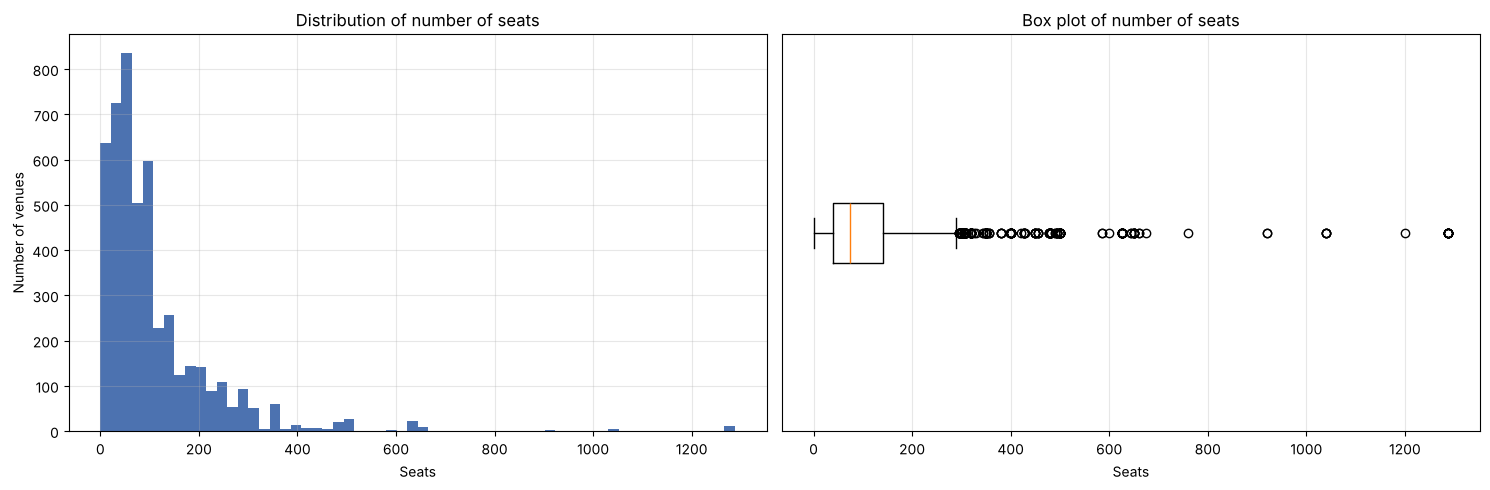

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

seats = df['seats'].dropna().astype(float)
axes[0].hist(seats, bins=60, color='#4C72B0')
axes[0].set_title('Distribution of number of seats')
axes[0].set_xlabel('Seats')
axes[0].set_ylabel('Number of venues')

axes[1].boxplot(seats, vert=False)
axes[1].set_title('Box plot of number of seats')
axes[1].set_xlabel('Seats')
axes[1].set_yticks([])
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# Outlier threshold by the 1.5 IQR rule, plus percentiles
q1, q3 = seats.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f'Upper IQR threshold: {upper:.0f} seats, above it: {(seats > upper).sum()} venues ({(seats > upper).mean():.1%})')
print('Percentiles:', seats.quantile([0.9, 0.95, 0.99]).to_dict())
print('Venues with 0 seats:', (seats == 0).sum())

# The largest values repeat across different venues
df.loc[df['seats'] >= 1000, ['name', 'category', 'address', 'seats']].sort_values('seats')

Upper IQR threshold: 290 seats, above it: 318 venues (6.6%)
Percentiles: {0.9: 240.0, 0.95: 307.0, 0.99: 625.0}
Venues with 0 seats: 136


,name,category,address,seats
2710,Vanya i Gogi,bar/pub,"Moscow, Izmaylovskoe highway, 71, bldg. A",1040
2719,Margarita,fast food,"Moscow, Izmaylovskoe highway, 71, bldg. A",1040
2767,Shokoladnitsa,coffee shop,"Moscow, Izmaylovskoe highway, 71, bldg. A",1040
2963,Matreshka,cafe,"Moscow, Izmaylovskoe highway, 71, bldg. A",1040
4226,RestoBar Argomento,canteen,"Moscow, Kutuzovskiy prospekt, 41, str. 1",1200
6511,DelonixCafe,restaurant,"Moscow, prospekt Vernadskogo, 94, bldg. 1",1288
6517,Yan Primus,restaurant,"Moscow, prospekt Vernadskogo, 121, bldg. 1",1288
6567,Myunger,pizzeria,"Moscow, prospekt Vernadskogo, 97, bldg. 1",1288
6634,One Price Coffee,coffee shop,"Moscow, prospekt Vernadskogo, 84, str. 1",1288
6651,GudBar,bar/pub,"Moscow, prospekt Vernadskogo, 97, bldg. 1",1288


In [33]:
# Typical number of seats per category — use the median since the distribution is heavily right-skewed
seats_by_cat = (df.dropna(subset=['seats'])
                  .groupby('category')['seats']
                  .agg(['median', 'mean', 'count'])
                  .astype(float).round(1)
                  .sort_values('median', ascending=False))
seats_by_cat.columns = ['median', 'mean', 'venues with data']
seats_by_cat

,median,mean,venues with data
category,,,
restaurant,86.0,121.9,1268.0
bar/pub,82.0,124.5,467.0
coffee shop,80.0,111.2,750.0
canteen,75.5,99.8,164.0
fast food,65.0,98.9,349.0
cafe,60.0,97.4,1217.0
pizzeria,55.0,94.5,427.0
bakery,50.0,89.4,148.0


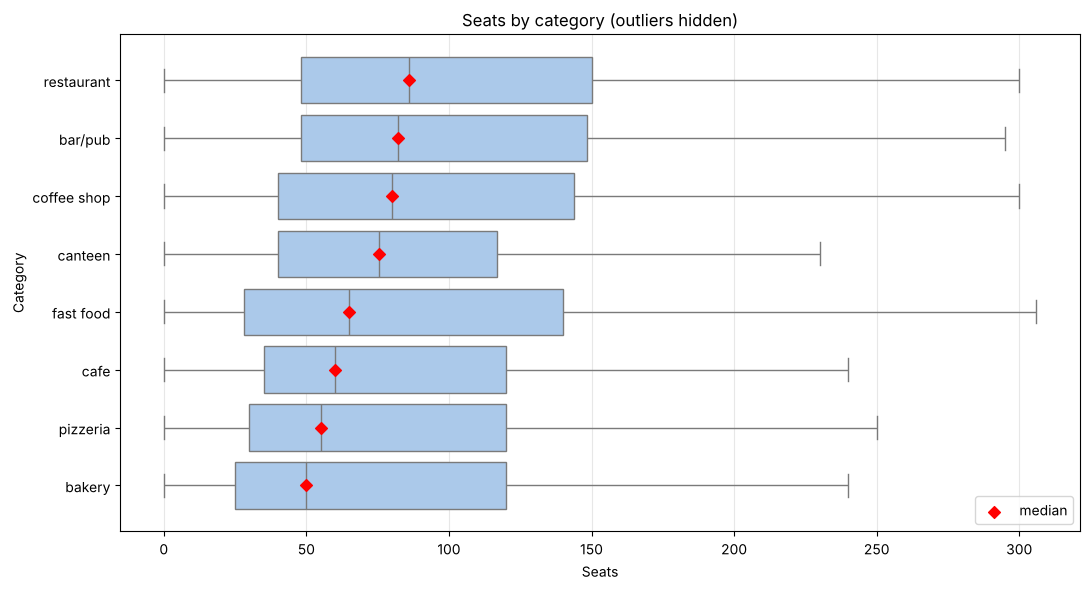

In [34]:
plt.figure(figsize=(11, 6))
order = seats_by_cat.index
sns.boxplot(data=df.dropna(subset=['seats']).astype({'seats': float}),
            x='seats', y='category', order=order, showfliers=False, color='#A1C9F4')
plt.scatter(seats_by_cat['median'], range(len(order)), color='red', marker='D', zorder=3, label='median')
plt.title('Seats by category (outliers hidden)')
plt.xlabel('Seats')
plt.ylabel('Category')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

The seats distribution is heavily right-skewed: median 75, mean 108. By the 1.5 IQR rule, values above 290 seats are outliers — 318 venues (about 7% of those with data); 99% of venues have at most 625 seats.

Where the anomalies come from:
- **Very large values (1000+)** repeat across different venues at the same addresses: e.g. 11 venues on Vernadsky Prospekt all have exactly 1288 seats, 4 venues at Izmailovskoye Shosse 71 have 1040. This looks like the total capacity of a shopping centre, food court or hotel complex, not of a single venue.
- **0 seats** for 136 venues — most likely takeaway-only spots or a data-entry error.

I didn't delete these values, but used the median to estimate the typical number of seats, since it is barely affected by outliers. Typical seats: restaurants — 86, bars/pubs — 82, coffee shops — 80, canteens — 75, fast food — 65, cafes — 60, pizzerias — 55, bakeries — 50.

---

### Task 5

Explore venue ratings. Visualise the distribution of average ratings by venue category. Do the average ratings differ a lot across food-service types?

In [35]:
rating_by_cat = df.groupby('category')['rating'].agg(['mean', 'median', 'std']).round(3).sort_values('mean')
rating_by_cat.columns = ['mean', 'median', 'std']
rating_by_cat

,mean,median,std
category,,,
fast food,4.050,4.2,0.561
cafe,4.124,4.2,0.566
canteen,4.211,4.3,0.454
bakery,4.268,4.3,0.386
coffee shop,4.278,4.3,0.372
restaurant,4.290,4.3,0.413
pizzeria,4.301,4.3,0.336
bar/pub,4.388,4.4,0.380


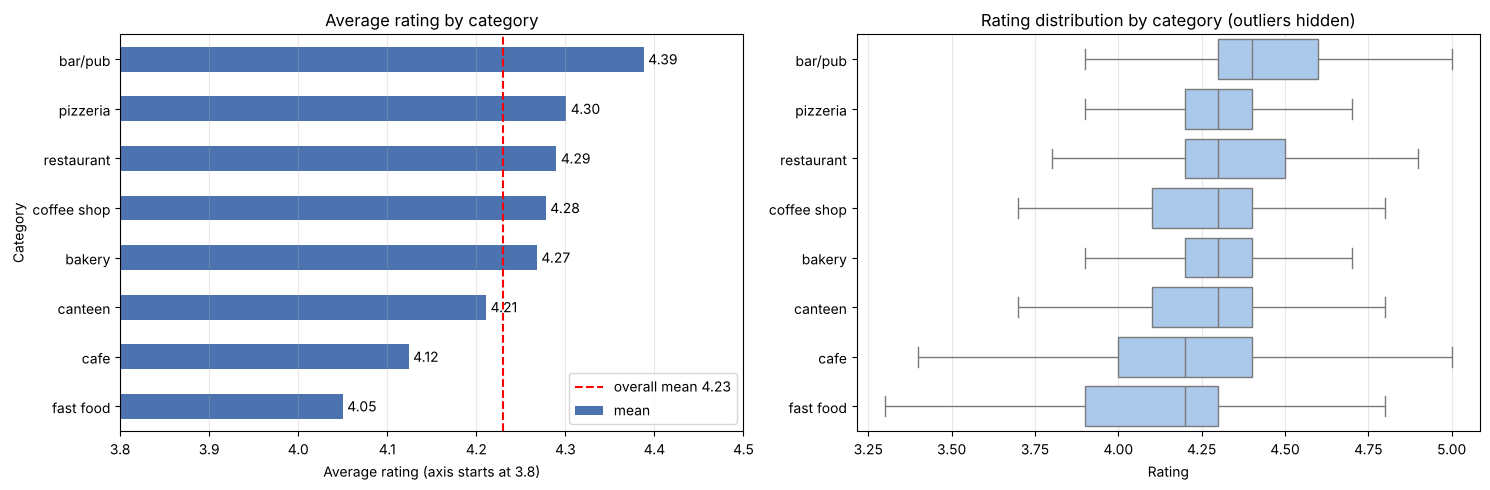

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = rating_by_cat['mean'].plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_xlim(3.8, 4.5)
axes[0].axvline(df['rating'].mean(), color='red', linestyle='--', label=f"overall mean {df['rating'].mean():.2f}")
for i, v in enumerate(rating_by_cat['mean']):
    ax.text(v + 0.005, i, f'{v:.2f}', va='center')
axes[0].set_title('Average rating by category')
axes[0].set_xlabel('Average rating (axis starts at 3.8)')
axes[0].set_ylabel('Category')
axes[0].legend()

sns.boxplot(data=df, x='rating', y='category', order=rating_by_cat.index[::-1], ax=axes[1],
            showfliers=False, color='#A1C9F4')
axes[1].set_title('Rating distribution by category (outliers hidden)')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('')
for a in axes:
    a.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Average ratings differ only slightly: from **4.05** for fast food to **4.39** for bars and pubs — a gap of only about 0.34 points. Medians are even closer — 4.2–4.4. For all categories, ratings mostly fall within 4.0–4.5, so Yandex Maps users generally give high scores. Fast food and cafes are slightly below the rest, bars/pubs, pizzerias and restaurants are the highest. The left chart's axis deliberately starts at 3.8 so the difference is visible; from zero the bars would look almost identical.

---

### Task 6

What do venue ratings correlate with most strongly? Build and visualise a correlation matrix of venue rating with various data: its category, location (Moscow administrative district), chain status, number of seats, price category and whether the venue is open 24/7. Choose the strongest relationship and check it.

In [37]:
# The features are mixed (categorical + numeric), so we use phik
corr_cols = ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']
corr_df = df[corr_cols].copy()
corr_df['seats'] = corr_df['seats'].astype(float)
corr_df['is_24_7'] = corr_df['is_24_7'].astype(int)

phik_matrix = corr_df.phik_matrix(interval_cols=['rating', 'seats'])
rating_corr = phik_matrix[['rating']].drop('rating').sort_values('rating', ascending=False)
rating_corr

,rating
price,0.220131
district,0.200765
category,0.190006
is_24_7,0.150653
chain,0.108370
seats,0.000000


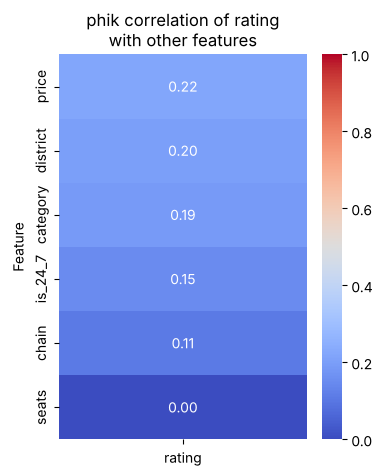

In [38]:
plt.figure(figsize=(4, 5))
sns.heatmap(rating_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1, cbar=True)
plt.title('phik correlation of rating\nwith other features')
plt.xlabel('')
plt.ylabel('Feature')
plt.show()

In [39]:
# The strongest link is with price category. Check how rating changes from low to high prices
price_order = ['low', 'medium', 'above average', 'high']
rating_by_price = df.groupby('price')['rating'].agg(['mean', 'median', 'count']).loc[price_order].round(3)
rating_by_price.columns = ['mean rating', 'median', 'venues']
rating_by_price

,mean rating,median,venues
price,,,
low,4.173,4.2,156
medium,4.298,4.3,2116
above average,4.386,4.4,564
high,4.437,4.4,478


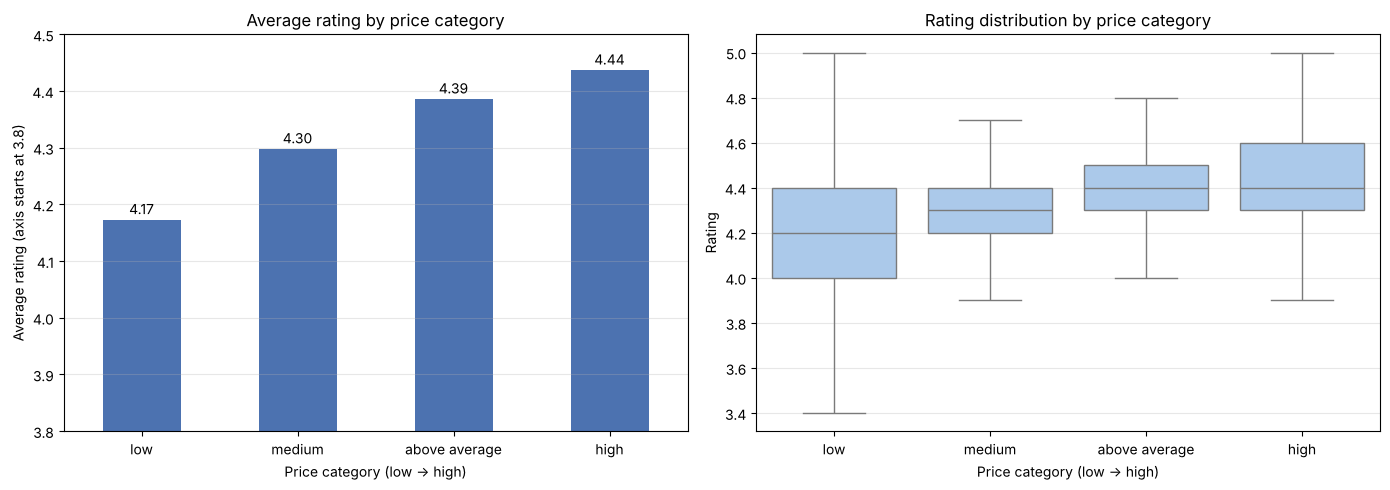

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_by_price['mean rating'].plot(kind='bar', ax=axes[0], color='#4C72B0', rot=0)
axes[0].set_ylim(3.8, 4.5)
for i, v in enumerate(rating_by_price['mean rating']):
    axes[0].text(i, v + 0.01, f'{v:.2f}', ha='center')
axes[0].set_title('Average rating by price category')
axes[0].set_xlabel('Price category (low → high)')
axes[0].set_ylabel('Average rating (axis starts at 3.8)')

sns.boxplot(data=df.dropna(subset=['price']), x='price', y='rating', order=price_order,
            ax=axes[1], showfliers=False, color='#A1C9F4')
axes[1].set_title('Rating distribution by price category')
axes[1].set_xlabel('Price category (low → high)')
axes[1].set_ylabel('Rating')
for a in axes:
    a.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

All relationships between rating and other features are weak: the phik coefficient is at most 0.22. Rating is most strongly associated with **price category (0.22)**, slightly less with district (0.20) and category (0.19). The link with 24/7 operation (0.15) and chain status (0.11) is weaker still, and there is practically none with the number of seats (0.00).

Checking the price relationship confirms it: the pricier the venue, the higher the rating — from 4.17 for low-price venues to 4.44 for expensive ones. The relationship is monotonic but small, and it's a correlation, not causation: expensive venues probably simply have better service and food. Also note that price category is known for only ~40% of venues.

---

### Task 7

Group the data by venue name and find the top 15 popular chains in Moscow. Calculate their average rating. Popularity means the number of the chain's venues in the region. Which category do they belong to? Accompany the result with suitable visualisations.

In [41]:
# Take only chain venues and group by the normalised name.
# A chain's category is the most frequent category among its locations
top_chains = (df[df['chain'] == 1]
                .groupby('name_norm')
                .agg(name=('name', lambda s: s.mode()[0]),
                     venues=('id', 'count'),
                     avg_rating=('rating', 'mean'),
                     category=('category', lambda s: s.mode()[0]))
                .sort_values('venues', ascending=False)
                .head(15)
                .reset_index(drop=True))
top_chains['avg_rating'] = top_chains['avg_rating'].round(2)
top_chains

,name,venues,avg_rating,category
0,Shokoladnitsa,120,4.18,coffee shop
1,Domino's Pitstsa,76,4.17,pizzeria
2,Dodo Pitstsa,74,4.29,pizzeria
3,One Price Coffee,71,4.06,coffee shop
4,Yandeks Lavka,69,3.87,restaurant
5,Cofix,65,4.08,coffee shop
6,Prime,50,4.12,restaurant
7,Khinkalnaya,44,4.32,cafe
8,KOFEPORT,42,4.15,coffee shop
9,Kulinarnaya lavka bratev Karavaevykh,39,4.39,cafe


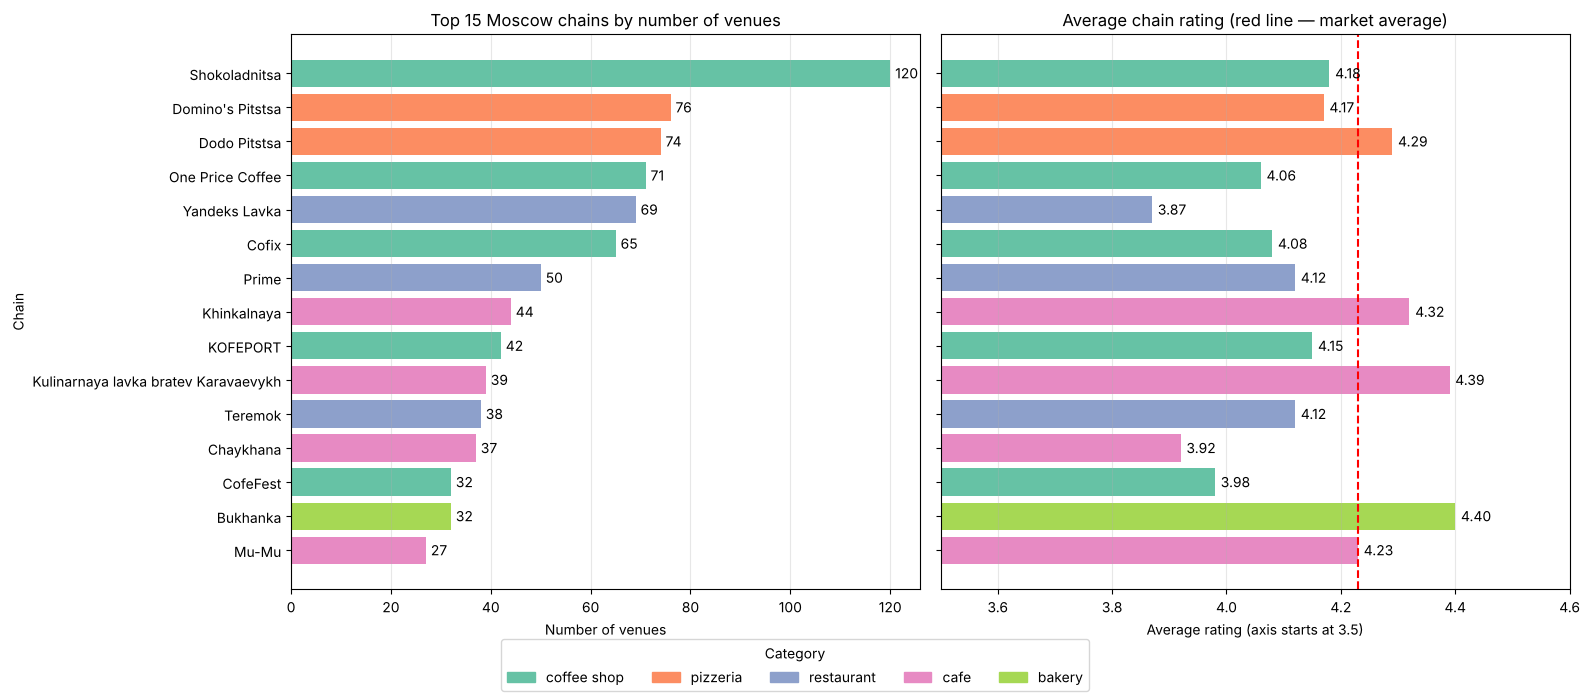

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
palette = dict(zip(top_chains['category'].unique(), sns.color_palette('Set2', top_chains['category'].nunique())))
plot_df = top_chains.iloc[::-1]
colors = plot_df['category'].map(palette)

axes[0].barh(plot_df['name'], plot_df['venues'], color=colors)
for i, v in enumerate(plot_df['venues']):
    axes[0].text(v + 1, i, str(v), va='center')
axes[0].set_title('Top 15 Moscow chains by number of venues')
axes[0].set_xlabel('Number of venues')
axes[0].set_ylabel('Chain')

axes[1].barh(plot_df['name'], plot_df['avg_rating'], color=colors)
axes[1].set_xlim(3.5, 4.6)
axes[1].axvline(df['rating'].mean(), color='red', linestyle='--')
for i, v in enumerate(plot_df['avg_rating']):
    axes[1].text(v + 0.01, i, f'{v:.2f}', va='center')
axes[1].set_title('Average chain rating (red line — market average)')
axes[1].set_xlabel('Average rating (axis starts at 3.5)')

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
fig.legend(handles, palette.keys(), title='Category', loc='lower center', ncol=len(palette))
for a in axes:
    a.grid(axis='x', alpha=0.3)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [43]:
top_chains['category'].value_counts()

category
coffee shop    5
cafe           4
restaurant     3
pizzeria       2
bakery         1
Name: count, dtype: int64

The largest chain is **Shokoladnitsa** (120 venues), followed by two pizza chains — Domino's Pitstsa (76) and Dodo Pitstsa (74), then One Price Coffee (71), Yandeks Lavka (69) and Cofix (65). The top 15 is dominated by **coffee shops** (5 chains), then cafes (4), restaurants (3), pizzerias (2) and one bakery — consistent with Task 3, where coffee shops and pizzerias were most often chains.

In terms of rating, the biggest chains are not better than the market: most have an average of 4.0–4.3, i.e. around or below the market average (4.23). Bukhanka (bakery, 4.40) and Kulinarnaya lavka bratev Karavaevykh (4.39) are the highest, Yandeks Lavka (3.87) and Chaykhana (3.92) the lowest. Chain size doesn't guarantee high ratings.

Two caveats: "Khinkalnaya" (khinkali house) and "Chaykhana" (teahouse) are generic names that may cover several unrelated small chains, and Yandeks Lavka (Yandex Lavka) is really a delivery service rather than a restaurant, though it's labelled that way in the data.

---

### Task 8

Explore the variation of the average bill (`middle_avg_bill`) depending on the Moscow district. Analyse prices in the Central Administrative District and others. How does distance from the centre affect prices? Accompany the result with suitable visualisations.

In [44]:
bill = df.dropna(subset=['middle_avg_bill'])
print('Venues with average-bill data:', len(bill))
bill['middle_avg_bill'].describe()

Venues with average-bill data: 3148


count     3148.000000
mean       958.262706
std       1009.825109
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

In [45]:
# Because of outliers (max 35,000 ₽) we compare districts by the median
bill_by_district = (bill.groupby('district_short')['middle_avg_bill']
                        .agg(['median', 'mean', 'count'])
                        .round(0)
                        .sort_values('median', ascending=False))
bill_by_district.columns = ['median, ₽', 'mean, ₽', 'venues']
bill_by_district

,"median, ₽","mean, ₽",venues
district_short,,,
Central,1000.0,1191.0,1060
West,1000.0,1056.0,305
North-West,700.0,822.0,157
North,650.0,928.0,322
South-West,600.0,793.0,235
East,575.0,821.0,260
North-East,500.0,717.0,301
South,500.0,834.0,314
South-East,450.0,654.0,194


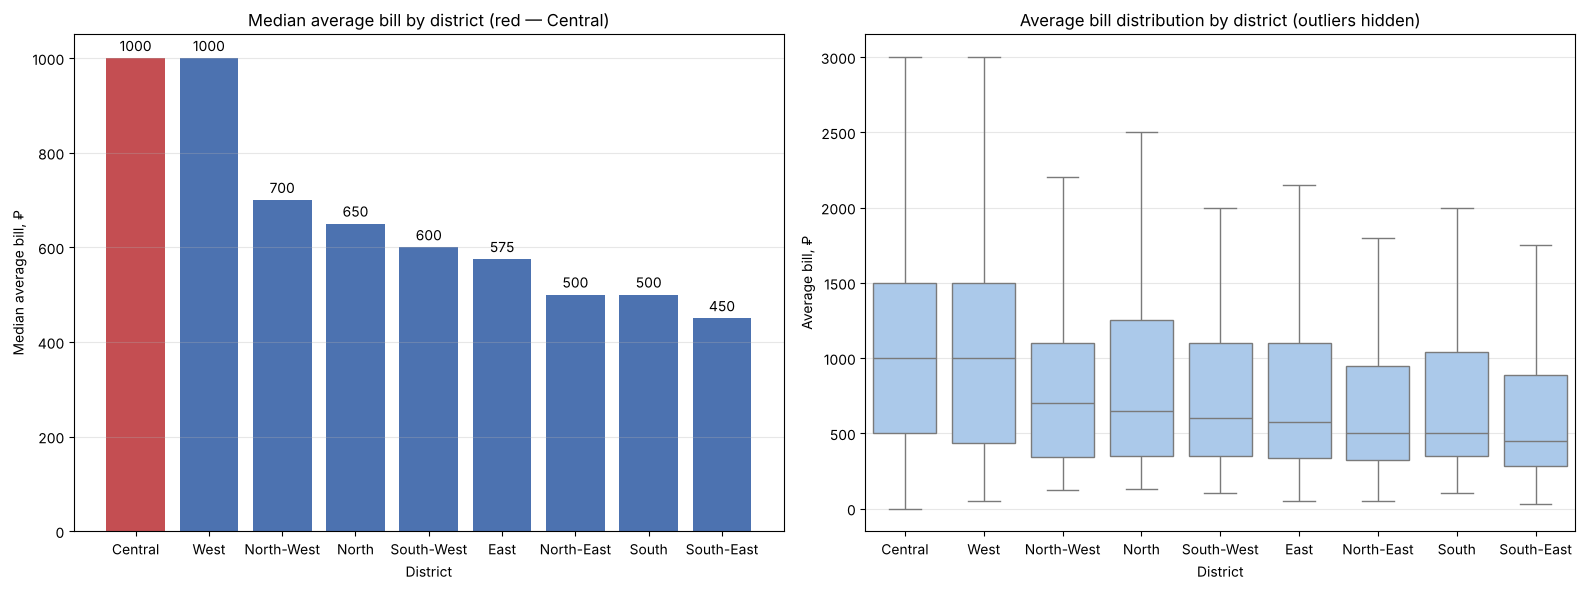

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = bill_by_district.index
colors = ['#C44E52' if d == 'Central' else '#4C72B0' for d in order]
axes[0].bar(order, bill_by_district['median, ₽'], color=colors)
for i, v in enumerate(bill_by_district['median, ₽']):
    axes[0].text(i, v + 15, f'{v:.0f}', ha='center')
axes[0].set_title('Median average bill by district (red — Central)')
axes[0].set_xlabel('District')
axes[0].set_ylabel('Median average bill, ₽')

sns.boxplot(data=bill, x='district_short', y='middle_avg_bill', order=order,
            ax=axes[1], showfliers=False, color='#A1C9F4')
axes[1].set_title('Average bill distribution by district (outliers hidden)')
axes[1].set_xlabel('District')
axes[1].set_ylabel('Average bill, ₽')
for a in axes:
    a.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
# Central district vs all other districts combined
cao_vs = (bill.assign(zone=np.where(bill['district_short'] == 'Central', 'Central', 'other districts'))
              .groupby('zone')['middle_avg_bill'].agg(['median', 'mean', 'count']).round(0))
cao_vs

,median,mean,count
zone,,,
Central,1000.0,1191.0,1060
other districts,600.0,840.0,2088


The average bill is known for 3149 venues; its distribution is heavily skewed (median 750 ₽, max 35,000 ₽), so I compare districts by the median.

The highest prices are in the **Central and Western districts — median 1000 ₽**. The Central district also has the highest mean (≈1190 ₽). Next come the North-West (700 ₽) and North (650 ₽). The most affordable are the South-East (450 ₽), North-East and South (500 ₽ each). The median bill in the centre is 1.5–2× higher than in the south-east.

Overall, distance from the centre lowers prices, but not uniformly — direction matters too. The West and North-West are expensive, while the South, East and South-East are cheap — matching the fact that western Moscow is considered more prestigious.

---

---

### Interim conclusion

Summarise the results, highlighting the most important ones in your opinion.

The most important findings:
- **The market is large and competitive**: 8399 venues, more than half are cafes (28%) and restaurants (24%), followed by coffee shops (17%).
- **The Central district is the hub**: 27% of all venues, the most restaurants and bars, and the highest average bill (median 1000 ₽). The Western district is equally expensive; the South-East, South and North-East are the cheapest.
- **There are fewer chain than non-chain venues** (38% vs 62%), but coffee shops, pizzerias and bakeries are more than half chains. Coffee shops dominate the top 15 chains, led by Shokoladnitsa.
- **The typical venue is small**: median 75 seats; restaurants and bars ~80–86, cafes and pizzerias 55–60. Values above 1000 seats are probably shopping-centre capacity rather than a single venue.
- **Ratings are high and similar** (4.05–4.39 on average). Rating is only weakly related to other features, most strongly to price category: expensive venues are rated slightly higher. Seats and chain status barely matter for rating.

## 4. Final conclusion and recommendations

Based on the exploratory analysis, formulate a final conclusion and recommendations for the client. Focus on the key points of the study.

Use this structure:

1. Overview of the work done.
2. Answers to the research questions, or main conclusions.
3. Recommendations based on the data analysis.

**1. Overview of the work done**

I analysed Yandex Maps and Yandex Business data on 8406 Moscow food-service venues (summer 2022). I merged the venue and price data, converted `seats` to an integer type, investigated missing values (and left them, since they're mostly caused by unfilled listings), removed 7 implicit duplicates (0.08%) and added an `is_24_7` round-the-clock flag. Then I explored categories, districts, chain status, seating, ratings, the biggest chains and the average bill.

**2. Main conclusions**

- The most common venues are cafes (28%), restaurants (24%) and coffee shops (17%).
- 27% of venues are in the Central district; restaurants dominate there, and bars/pubs are 2.5× more common (by share) than in other districts.
- 62% of venues are non-chain. Bakeries (61%), pizzerias (52%) and coffee shops (51%) are most often chains, bars/pubs (22%) least often.
- The typical number of seats is 50–86 depending on category; there are anomalies (0 seats and 1000+ seats — probably shopping-centre capacity).
- Average rating barely depends on category (4.05–4.39). Rating is most strongly related to price category (phik 0.22): expensive venues are rated higher (4.44 vs 4.17 for cheap ones).
- The largest chains are Shokoladnitsa, Domino's, Dodo Pizza and One Price Coffee; coffee shops dominate the top 15. Big chains are mostly not rated above the market average.
- The average bill is highest in the Central and Western districts (median 1000 ₽) and lowest in the South-East (450 ₽). Prices fall with distance from the centre, but the western direction stays expensive.

**3. Recommendations**

- **Format.** If the goal is a higher rating and bill, consider a restaurant or bar in the "above average"/"high" price segment: these get the best ratings, and there's demand for them in the centre. A coffee shop or pizzeria is a clear format, but big chains are already strong there, so it's harder for a new independent venue to stand out.
- **District.** The Central district has the most footfall and a high bill, but also the densest competition. A good alternative is the Western district: the bill is just as high (median 1000 ₽) with almost 3× fewer venues. The North-West is the least saturated district (409 venues) with an above-average bill and is also worth considering.
- **Size.** Aim for the 60–90 seats typical of the format.
- **Quality over scale.** Rating depends little on chain status or size, so invest in food and service — expensive venues with good service consistently get higher scores.
- **Limitations.** Prices are known for only ~40% of venues and seats for ~57%, so the conclusions should be checked on fuller data (e.g. specific streets and footfall) before a final decision.